# CNNSE (from scratch) — Four-Breed Dog Classification

Thin driver notebook over the `CNNBuildScratch/src` pipeline — no duplicated code here:

- **Data:** pre-split `input/Cleaned Dataset` (700 train / 150 val / 150 test per class), provisioned into `outputs/*.csv` by `src/dataset.py::ensure_split_csvs`
- **Model:** `src/model.py::CNNSE` — 11.26M params, residual blocks + squeeze-excitation, no pretrained weights
- **Training:** `src/train.py::train_one_seed` — RandAugment + RandomErasing, MixUp/CutMix, AdamW + selective weight decay, 5-epoch warmup → cosine, EMA, best checkpoint by val macro-F1
- **Run:** 1 seed (42) × up to 150 epochs on the RTX 5060 (early stop after 12 stagnant epochs), then TTA validation (step 7, `input/Cleaned Dataset/validation`) and one-shot TTA test (step 8, `input/Cleaned Dataset/test`)
- **Report (step 9):** build curves + TTA figures/CSV for the seed(s) trained in this run (`SEEDS`, from `outputs/logs/train_seed*.log` + `outputs/metrics.json`)
- **ROC / threshold (step 10):** one-vs-rest ROC on validation TTA, Youden thresholds per class, evaluate on test

**How to run (Windows, GPU .venv):**
1. Kernel: `Python 3 (ipykernel)` from `CNNBuildScratch/.venv` (torch 2.11.0+cu128, Python 3.14).
2. `TRAIN = True` in the setup cell → **Run All** (~40-60 min). `TRAIN = False` → re-evaluates the saved checkpoint (~1-2 min).

Outputs go to `CNNBuildScratch/outputs/`.

In [1]:
# 1. Setup — thin driver over src/
import json
import sys
import time
from pathlib import Path
from types import SimpleNamespace

print("Python executable:", sys.executable)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch._utils  # force-load before AdamW (avoids stale-kernel AttributeError)
from IPython.display import Image as IPyImage, display

TRACK_DIR = Path.cwd().resolve()
if not (TRACK_DIR / "src" / "dataset.py").is_file():
    TRACK_DIR = TRACK_DIR / "CNNBuildScratch"
SRC_DIR = TRACK_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import importlib
import dataset
import model as _model_mod
import train as trainer

# Always reload src/ after edits — stale kernel otherwise keeps old train.py (old AdamW path)
dataset = importlib.reload(dataset)
_model_mod = importlib.reload(_model_mod)
trainer = importlib.reload(trainer)
from model import CNNSE, count_params

# --- config (mirrors src/train.py CLI defaults) ---
SEEDS = [42]  # single seed
EPOCHS = 150
BATCH_SIZE = 32
LR = 1e-3
WD = 5e-2
WARMUP_EPOCHS = 5
DROPOUT = 0.3
LABEL_SMOOTHING = 0.1
MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0
MIX_PROB = 0.5
EMA_DECAY = 0.999
NUM_WORKERS = 0
EARLY_STOP_PATIENCE = 12  # halt if val macro-F1 doesn't improve for 12 consecutive epochs (0 = off)

TRAIN = True  # False: re-eval the saved checkpoint (~1 min). True: train 1 seed x 150 epochs.

INPUT_DIR = dataset.INPUT_DIR
OUTPUT_DIR = dataset.OUTPUT_DIR
CLASS_NAMES = trainer.CLASS_NAMES

device = trainer.get_device()
trainer.set_seed(SEEDS[0])
torch.backends.cudnn.benchmark = True
print(f"TRACK_DIR = {TRACK_DIR}")
print(f"INPUT_DIR = {INPUT_DIR}  exists={INPUT_DIR.is_dir()}")
print(f"OUTPUT_DIR= {OUTPUT_DIR}")
print(f"Device    = {device} | torch {torch.__version__} | TRAIN={TRAIN}")
if device.type == "cuda":
    print(f"GPU       = {torch.cuda.get_device_name(0)} (sm {torch.cuda.get_device_capability(0)})")

Python executable: c:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch\.venv\Scripts\python.exe
TRACK_DIR = C:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch
INPUT_DIR = C:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch\input\Cleaned Dataset  exists=True
OUTPUT_DIR= C:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch\outputs
Device    = cuda | torch 2.11.0+cu128 | TRAIN=True
GPU       = NVIDIA GeForce RTX 5060 (sm (12, 0))


## 2. Data split

`src/dataset.py::ensure_split_csvs` indexes the pre-split `input/Cleaned Dataset` folders (`train` → `train.csv`, `validation` → `val.csv`, `test` → `test.csv`) and recomputes train mean/std when the CSVs are missing or stale. No re-splitting — the official folders are used as-is.

In [3]:
# 2. Data split — provisioned from input/Cleaned Dataset by src/dataset.py
dataset.ensure_split_csvs()
meta = json.loads((OUTPUT_DIR / "split_meta.json").read_text(encoding="utf-8"))
print(json.dumps(meta["class_counts"], indent=2))
print(f"mean={meta['mean']}\nstd ={meta['std']}")
seen, ok = set(), True
for name in ("train", "val", "test"):
    df = pd.read_csv(OUTPUT_DIR / f"{name}.csv")
    overlap = len(seen.intersection(df["path"]))
    print(f"{name}: {len(df)} images | labels={sorted(df['label'].unique().tolist())} | overlap-with-previous-splits={overlap}")
    ok &= overlap == 0 and len(df) == df["path"].nunique()
    seen.update(df["path"])
print("OK" if ok else "VERIFICATION FAILED")

{
  "train": {
    "golden_retriever": 700,
    "Cardigan": 700,
    "Labrador_retriever": 700,
    "French_bulldog": 700
  },
  "val": {
    "Labrador_retriever": 150,
    "Cardigan": 150,
    "golden_retriever": 150,
    "French_bulldog": 150
  },
  "test": {
    "golden_retriever": 150,
    "Labrador_retriever": 150,
    "French_bulldog": 150,
    "Cardigan": 150
  }
}
mean=[0.5261064171791077, 0.4858545660972595, 0.4366661310195923]
std =[0.25265783071517944, 0.24950776994228363, 0.2556225657463074]
train: 2800 images | labels=[0, 1, 2, 3] | overlap-with-previous-splits=0
val: 600 images | labels=[0, 1, 2, 3] | overlap-with-previous-splits=0
test: 600 images | labels=[0, 1, 2, 3] | overlap-with-previous-splits=0
OK


## 3. Loaders sanity check

Transforms + loaders come from `src/dataset.py` (RandAugment + RandomErasing on train; plain resize on eval).

In [4]:
# 3. Loaders (src/dataset.py)
train_loader, val_loader, test_loader, mean, std = dataset.make_loaders(
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEEDS[0]
)
xb, yb = next(iter(train_loader))
print(f"batch images: {tuple(xb.shape)}  labels: {yb[:8].tolist()}")
assert xb.shape[1:] == (3, dataset.IMAGE_SIZE, dataset.IMAGE_SIZE)
print("Preprocessing + label check OK")

batch images: (32, 3, 224, 224)  labels: [0, 3, 3, 1, 2, 1, 3, 0]
Preprocessing + label check OK


## 4. CNNSE (from scratch)

`src/model.py::CNNSE` — 18-layer-style residual CNN with squeeze-excitation in every block, GAP → dropout → linear.

In [14]:
# 4. Model (src/model.py)
net = CNNSE(num_classes=len(CLASS_NAMES), dropout=DROPOUT).to(device)
print(f"CNNSE params: {count_params(net) / 1e6:.2f}M")
out = net(torch.randn(2, 3, dataset.IMAGE_SIZE, dataset.IMAGE_SIZE, device=device))
print("forward:", tuple(out.shape))
del net, out
if device.type == "cuda":
    torch.cuda.empty_cache()

CNNSE params: 11.26M
forward: (2, 4)


## 5. Train — 1 seed × up to 150 epochs (early stop: 12 epochs without improvement)

`src/train.py::train_one_seed` with the namespace below (same defaults as the CLI). Checkpoint = best EMA weights by val macro-F1, saved to `outputs/best_CNN_se_seed42.pt`.

CNNSE params: 11.26M
[seed 42] epoch 001/150 lr=2.00e-04 train_loss=1.4022 train_acc=0.2721 val_loss=1.3867 val_acc=0.2400 val_f1=0.1065 (38s) *
[seed 42] epoch 002/150 lr=4.00e-04 train_loss=1.3576 train_acc=0.3264 val_loss=1.3858 val_acc=0.2433 val_f1=0.1416 (57s) *
[seed 42] epoch 003/150 lr=6.00e-04 train_loss=1.3522 train_acc=0.3271 val_loss=1.3846 val_acc=0.2567 val_f1=0.1741 (75s) *
[seed 42] epoch 004/150 lr=8.00e-04 train_loss=1.3459 train_acc=0.3254 val_loss=1.3829 val_acc=0.2650 val_f1=0.1567 (93s)
[seed 42] epoch 005/150 lr=1.00e-03 train_loss=1.3297 train_acc=0.3404 val_loss=1.3807 val_acc=0.2617 val_f1=0.1260 (111s)
[seed 42] epoch 006/150 lr=1.00e-03 train_loss=1.3288 train_acc=0.3393 val_loss=1.3782 val_acc=0.2617 val_f1=0.1256 (128s)
[seed 42] epoch 007/150 lr=1.00e-03 train_loss=1.3050 train_acc=0.3554 val_loss=1.3754 val_acc=0.2567 val_f1=0.1164 (146s)
[seed 42] epoch 008/150 lr=9.99e-04 train_loss=1.2916 train_acc=0.3743 val_loss=1.3717 val_acc=0.2617 val_f1=0.1307 

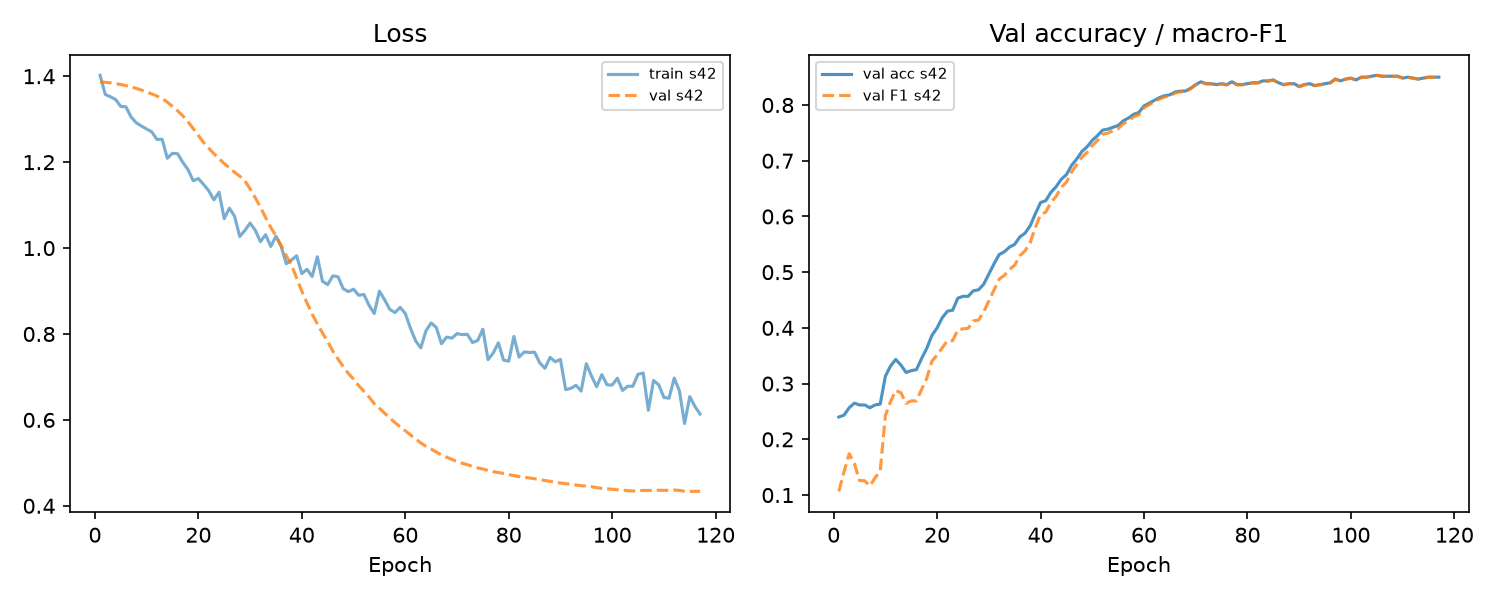

--- C:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch\outputs\logs\train_seed42.log ---
[seed 42] start epochs=150 bs=32 lr=0.001 wd=0.05 warmup=5 mix_prob=0.5 device=cuda
[seed 42] epoch 001/150 lr=2.00e-04 train_loss=1.4022 train_acc=0.2721 val_loss=1.3867 val_acc=0.2400 val_f1=0.1065 (38s) *
[seed 42] epoch 002/150 lr=4.00e-04 train_loss=1.3576 train_acc=0.3264 val_loss=1.3858 val_acc=0.2433 val_f1=0.1416 (57s) *
[seed 42] epoch 003/150 lr=6.00e-04 train_loss=1.3522 train_acc=0.3271 val_loss=1.3846 val_acc=0.2567 val_f1=0.1741 (75s) *
[seed 42] epoch 004/150 lr=8.00e-04 train_loss=1.3459 train_acc=0.3254 val_loss=1.3829 val_acc=0.2650 val_f1=0.1567 (93s)
[seed 42] epoch 005/150 lr=1.00e-03 train_loss=1.3297 train_acc=0.3404 val_loss=1.3807 val_acc=0.2617 val_f1=0.1260 (111s)
[seed 42] epoch 006/150 lr=1.00e-03 train_loss=1.3288 train_acc=0.3393 val_loss=1.3782 val_acc=0.2617 val_f1=0.1256 (128s)
[seed 42] epoch 007/150 lr=1.00e-03 train_loss=1.3050 train_acc=0.3554 val_los

In [5]:
import torch._utils  # force-load before AdamW (avoids stale-kernel AttributeError
# 5. Train (src/train.py recipe: warmup -> cosine 150 epochs, EMA, MixUp/CutMix
args = SimpleNamespace(
    epochs=EPOCHS, seeds=SEEDS, batch_size=BATCH_SIZE, lr=LR, wd=WD,
    warmup_epochs=WARMUP_EPOCHS, dropout=DROPOUT, label_smoothing=LABEL_SMOOTHING,
    mixup_alpha=MIXUP_ALPHA, cutmix_alpha=CUTMIX_ALPHA, mix_prob=MIX_PROB,
    ema_decay=EMA_DECAY, num_workers=NUM_WORKERS, smoke=False, max_batches=0, eval_only=False,
    early_stop_patience=EARLY_STOP_PATIENCE,
)

if TRAIN:
    runs = [trainer.train_one_seed(args, s, device) for s in SEEDS]
    trainer.plot_curves(runs, OUTPUT_DIR / "training_curves.png")
    display(IPyImage(filename=str(OUTPUT_DIR / "training_curves.png")))
else:
    runs = []
    p = OUTPUT_DIR / f"best_CNN_se_seed{SEEDS[0]}.pt"
    print(f"TRAIN=False — using existing checkpoint: {p}  exists={p.is_file()}")

# Per-epoch log — streamed live above during training; re-printed here from the saved log file
for s in SEEDS:
    log_path = OUTPUT_DIR / "logs" / f"train_seed{s}.log"
    if log_path.is_file():
        print(f"--- {log_path} ---")
        print(log_path.read_text(encoding="utf-8"))
    else:
        print(f"No log file at {log_path} — run with TRAIN=True first.")

## 7. Validation — `input/Cleaned Dataset/validation`

`src/train.py::run_validation` evaluates the saved best checkpoint(s) on the validation split with the same TTA protocol as the test step (mean softmax over {224, hflip, 256-center-crop, hflip}), per seed + ensemble, writes `outputs/confusion_matrix_val.png`, and prints a per-class report.

Note: the val split was already used for checkpoint selection during training, so these numbers are mildly optimistic — the one-shot test in step 8 remains the final estimate.

[eval] seed 42 single+TTA val acc=0.8783 f1=0.8779
[eval] ENSEMBLE+TTA val acc=0.8783 f1=0.8779
[eval] val ensemble per-class report:
                    precision    recall  f1-score   support

    French_bulldog       0.86      0.83      0.84       150
          Cardigan       0.93      0.93      0.93       150
Labrador_retriever       0.84      0.83      0.83       150
  golden_retriever       0.88      0.93      0.91       150

          accuracy                           0.88       600
         macro avg       0.88      0.88      0.88       600
      weighted avg       0.88      0.88      0.88       600



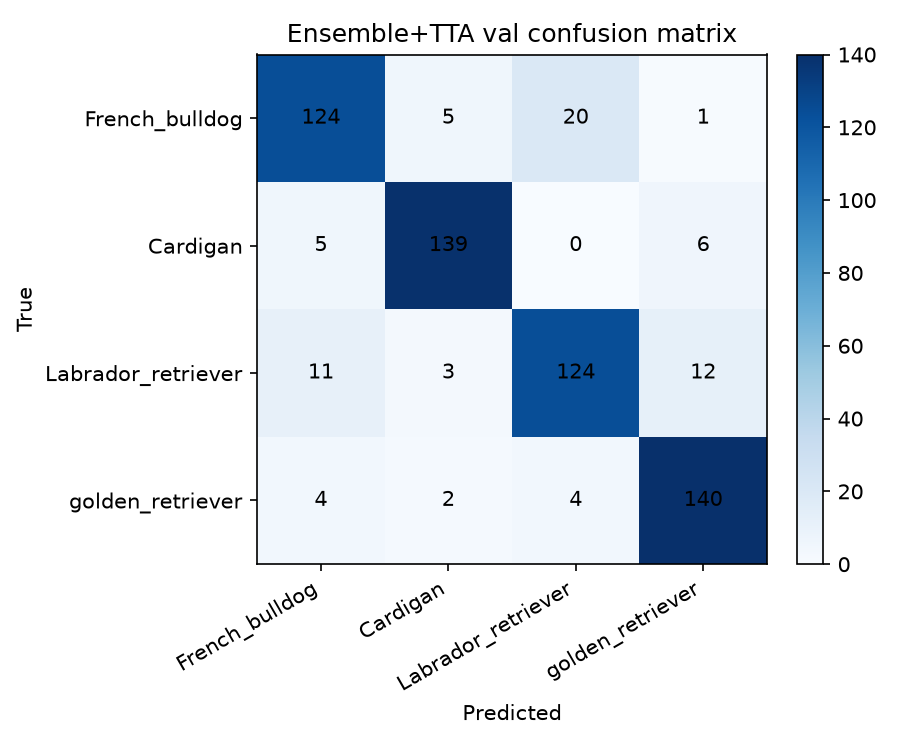

In [6]:
# 7. Validation (src/train.py::run_validation) — TTA on input/Cleaned Dataset/validation
val_results = trainer.run_validation(args, device)
display(IPyImage(filename=str(OUTPUT_DIR / "confusion_matrix_val.png")))

## 8. One-shot test evaluation (TTA) — `input/Cleaned Dataset/test`

The test set is evaluated exactly once via `src/train.py::run_final_eval`: mean softmax over {224, hflip, 256-center-crop, hflip}. Validation (step 7) was used only for checkpoint selection and sanity checks.

[eval] seed 42 single+TTA test acc=0.8650 f1=0.8642
[eval] ENSEMBLE+TTA test acc=0.8650 f1=0.8642
Wrote C:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch\outputs\metrics.json


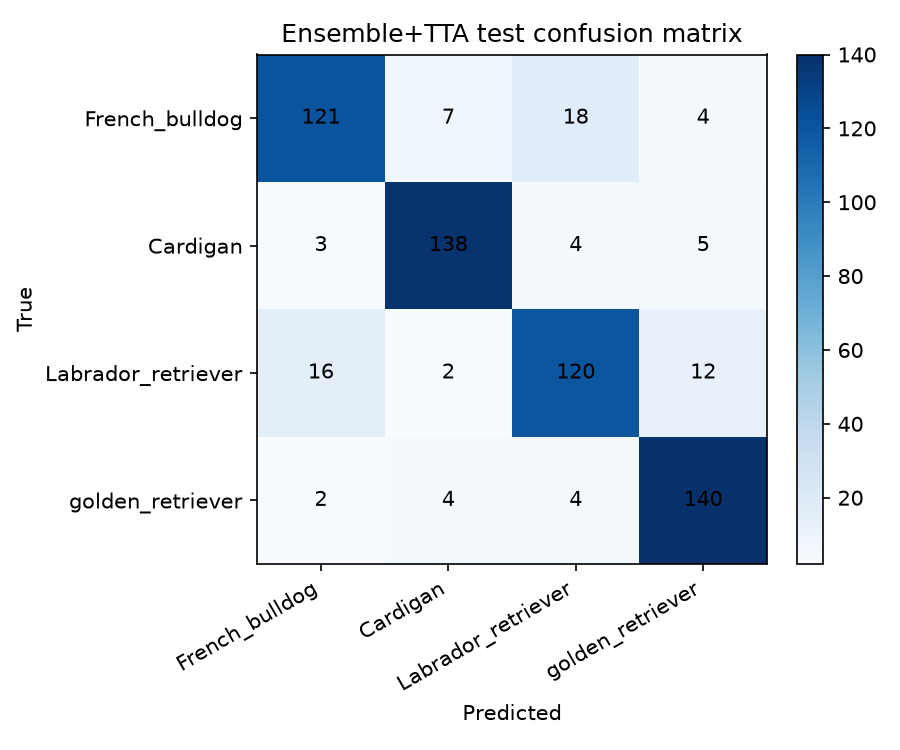

In [7]:
# 8. TTA one-shot test (src/train.py::run_final_eval)
eval_results = trainer.run_final_eval(args, device)
metrics = {
    "config": {k: v for k, v in vars(args).items()},
    "device": str(device),
    "class_counts": json.loads((OUTPUT_DIR / "split_meta.json").read_text())["class_counts"],
    "runs": (
        [{k: r[k] for k in ("seed", "best_val_macro_f1", "best_epoch", "train_seconds")} for r in runs]
        if runs
        else "TRAIN=False (checkpoint re-used)"
    ),
    "validation": val_results,
    **eval_results,
}
with (OUTPUT_DIR / "metrics.json").open("w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print(f"Wrote {OUTPUT_DIR / 'metrics.json'}")
display(IPyImage(filename=str(OUTPUT_DIR / "confusion_matrix.png")))

## 9. Report dataset for this run’s seed(s)

Builds the report figures/CSV from **this notebook run** (`SEEDS`, currently seed 42):

- Parses `outputs/logs/train_seed{seed}.log` → curves CSV + 3-panel figure (loss / accuracy / sec-per-epoch)
- Loads `outputs/metrics.json` (steps 7–8) → TTA confusion matrix + test accuracy / macro-F1 bars

Does **not** retrain. Writes `outputs/report_run_*`.

{
  "seeds": [
    42
  ],
  "source_logs": [
    "C:\\Users\\f5421441\\Downloads\\CNNBuildScratch\\CNNBuildScratch\\outputs\\logs\\train_seed42.log"
  ],
  "source_metrics": "C:\\Users\\f5421441\\Downloads\\CNNBuildScratch\\CNNBuildScratch\\outputs\\metrics.json",
  "n_seeds": 1,
  "epochs_per_seed": {
    "42": 117
  },
  "artifacts": {
    "curves_csv": "C:\\Users\\f5421441\\Downloads\\CNNBuildScratch\\CNNBuildScratch\\outputs\\report_run_curves.csv",
    "metrics_json": "C:\\Users\\f5421441\\Downloads\\CNNBuildScratch\\CNNBuildScratch\\outputs\\report_run_metrics.json",
    "training_curves_png": "C:\\Users\\f5421441\\Downloads\\CNNBuildScratch\\CNNBuildScratch\\outputs\\report_run_training_curves.png",
    "confusion_matrix_png": "C:\\Users\\f5421441\\Downloads\\CNNBuildScratch\\CNNBuildScratch\\outputs\\report_run_confusion_matrix.png",
    "test_tta_bars_png": "C:\\Users\\f5421441\\Downloads\\CNNBuildScratch\\CNNBuildScratch\\outputs\\report_run_test_tta_bars.png"
  }
}


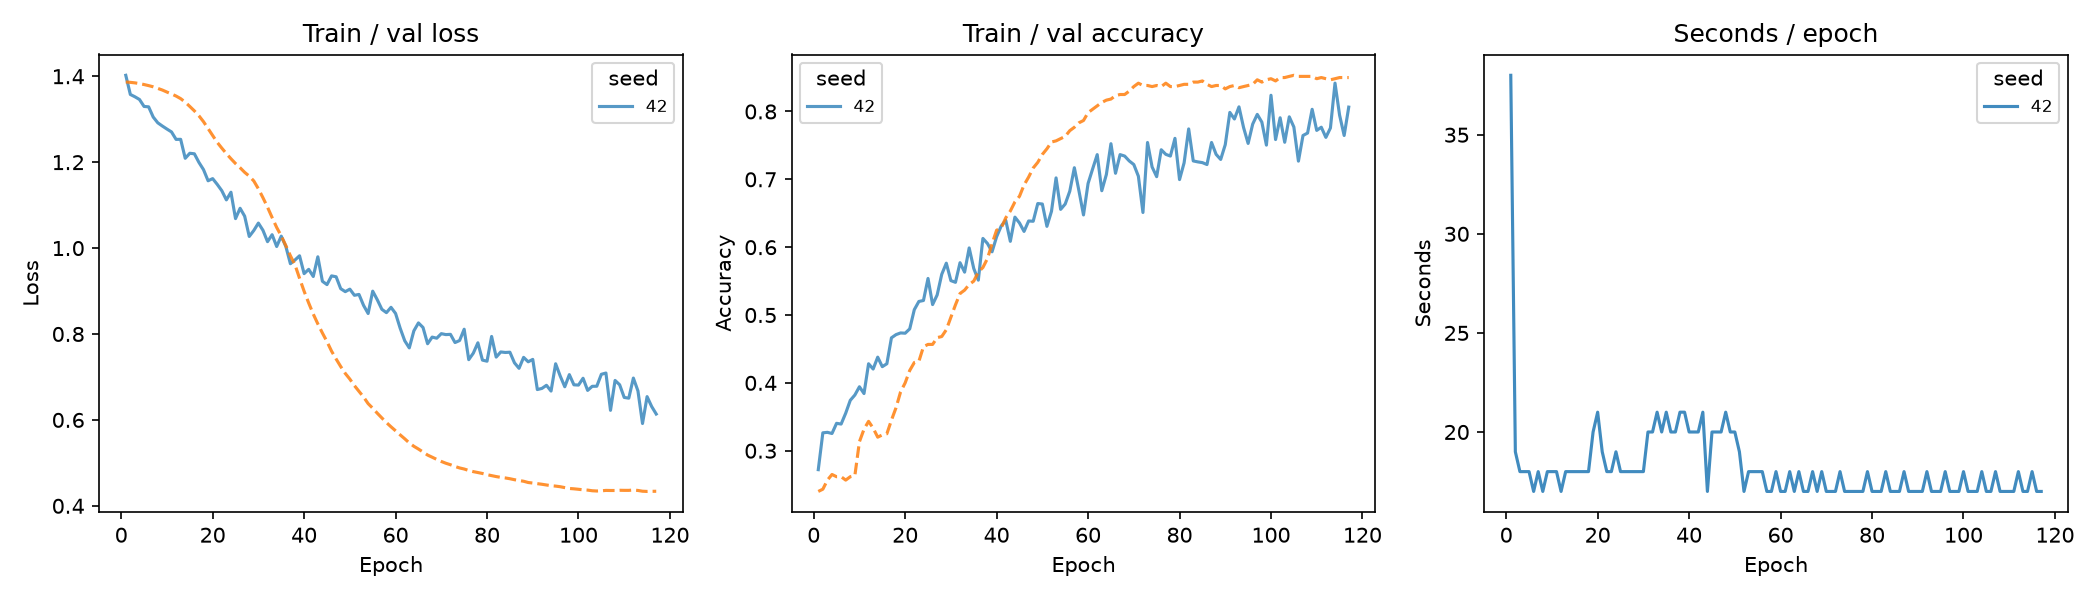

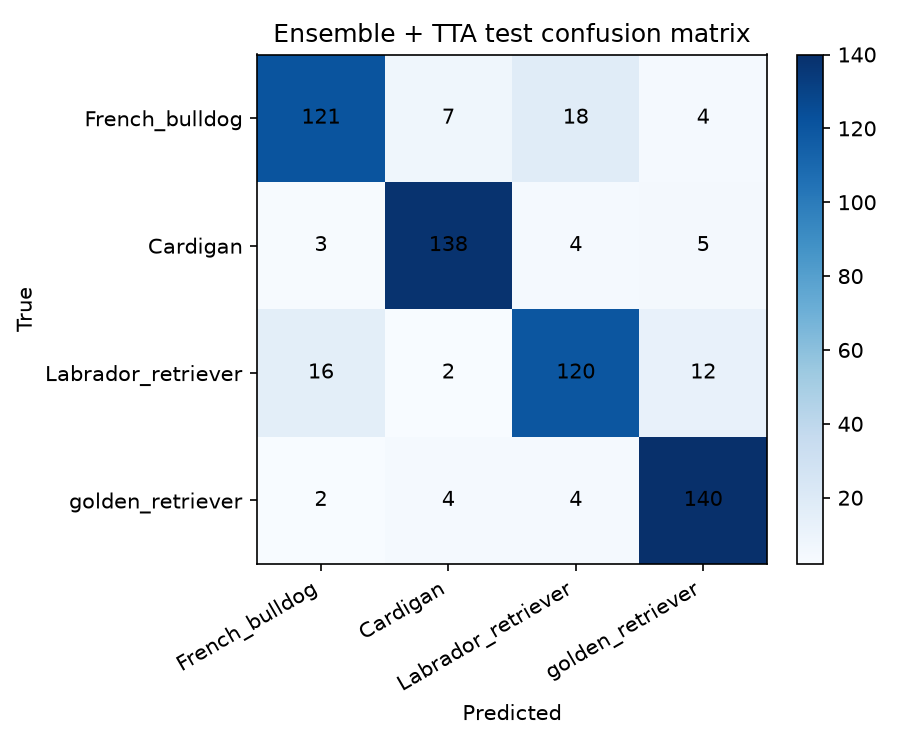

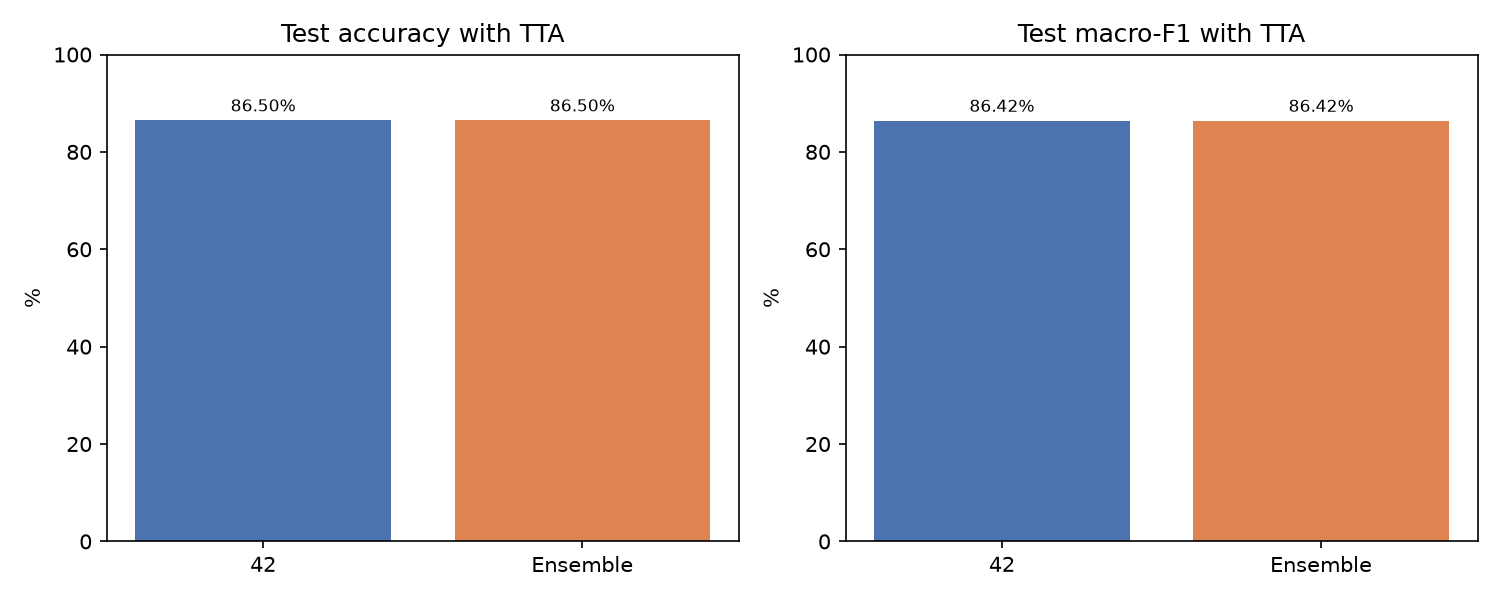

curves CSV: C:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch\outputs\report_run_curves.csv
metrics JSON: C:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch\outputs\report_run_metrics.json


In [9]:
# 9. Report for this run's SEEDS (src/train.py::build_run_report)
trainer = importlib.reload(trainer)
report = trainer.build_run_report(seeds=SEEDS, metrics_path=OUTPUT_DIR / "metrics.json")
for key in ("training_curves_png", "confusion_matrix_png", "test_tta_bars_png"):
    display(IPyImage(filename=report["artifacts"][key]))
print("curves CSV:", report["artifacts"]["curves_csv"])
print("metrics JSON:", report["artifacts"]["metrics_json"])

## 10. ROC curves + threshold selection

`src/train.py::run_roc_threshold_analysis`:

1. Computes ensemble TTA softmax probs on **validation** and **test**
2. Plots one-vs-rest ROC per breed (val)
3. Selects each class threshold by **Youden’s J** (`TPR − FPR`) on validation
4. Applies `argmax(p − thr)` (fallback to `argmax(p)` if no class passes) and reports val/test accuracy + macro-F1

Writes `outputs/roc_val.png` and `outputs/roc_thresholds.json`.

[roc] computing validation TTA probabilities for threshold selection...
[roc] computing test TTA probabilities for hold-out evaluation...
[roc] French_bulldog: AUC=0.9729 Youden thr=0.1763 (TPR=0.947, FPR=0.089)
[roc] Cardigan: AUC=0.9903 Youden thr=0.2496 (TPR=0.953, FPR=0.033)
[roc] Labrador_retriever: AUC=0.9675 Youden thr=0.2883 (TPR=0.880, FPR=0.096)
[roc] golden_retriever: AUC=0.9868 Youden thr=0.4262 (TPR=0.947, FPR=0.044)
[roc] val  argmax F1=0.8779 | thresholded F1=0.8783
[roc] test argmax F1=0.8642 | thresholded F1=0.8794
[roc] wrote C:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch\outputs\roc_val.png
[roc] wrote C:\Users\f5421441\Downloads\CNNBuildScratch\CNNBuildScratch\outputs\roc_thresholds.json


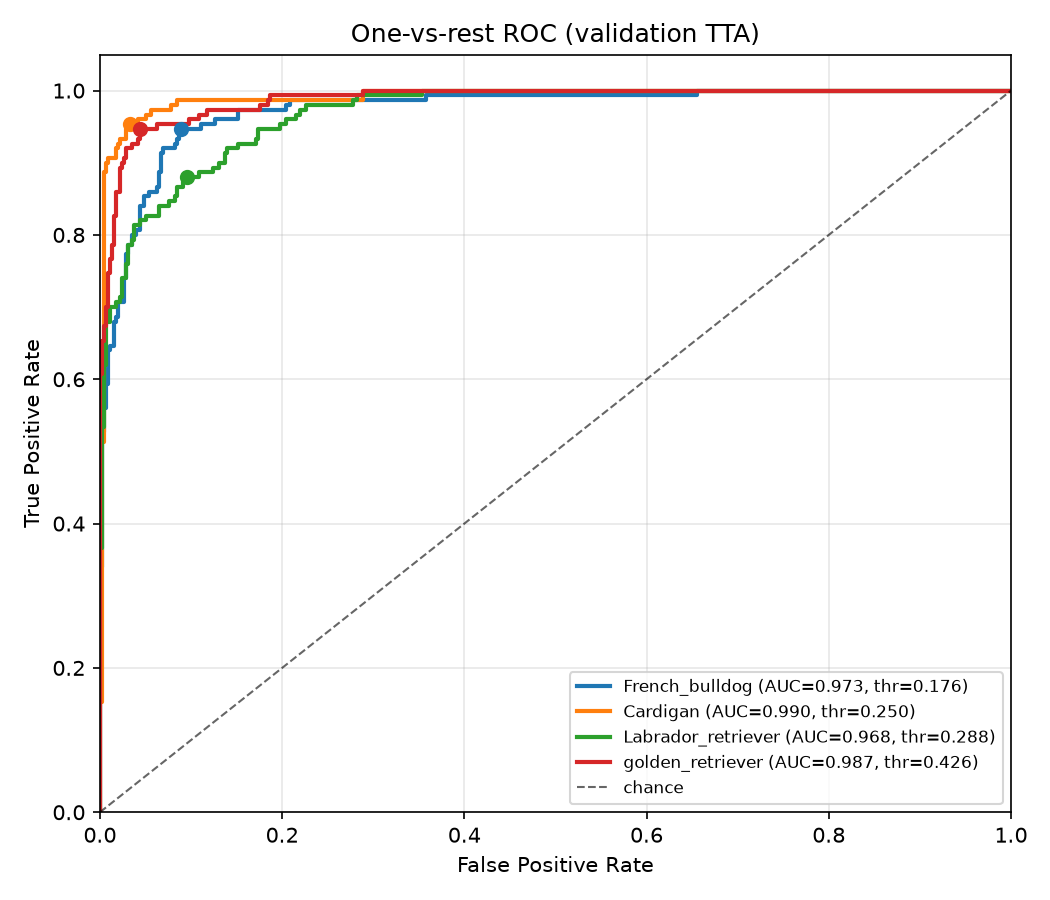

{
  "classes": [
    {
      "class_index": 0,
      "class_name": "French_bulldog",
      "threshold": 0.17633798718452454,
      "auc": 0.9728592592592592,
      "tpr_at_threshold": 0.9466666666666667,
      "fpr_at_threshold": 0.08888888888888889,
      "youden_j": 0.8577777777777778
    },
    {
      "class_index": 1,
      "class_name": "Cardigan",
      "threshold": 0.24962806701660156,
      "auc": 0.9903407407407407,
      "tpr_at_threshold": 0.9533333333333334,
      "fpr_at_threshold": 0.03333333333333333,
      "youden_j": 0.92
    },
    {
      "class_index": 2,
      "class_name": "Labrador_retriever",
      "threshold": 0.28829580545425415,
      "auc": 0.9675407407407408,
      "tpr_at_threshold": 0.88,
      "fpr_at_threshold": 0.09555555555555556,
      "youden_j": 0.7844444444444445
    },
    {
      "class_index": 3,
      "class_name": "golden_retriever",
      "threshold": 0.42615798115730286,
      "auc": 0.9867851851851852,
      "tpr_at_threshold": 0.94666666

In [10]:
# 10. ROC + Youden thresholds (src/train.py::run_roc_threshold_analysis)
trainer = importlib.reload(trainer)
roc_results = trainer.run_roc_threshold_analysis(args, device)
display(IPyImage(filename=str(OUTPUT_DIR / "roc_val.png")))
print(json.dumps({
    "classes": roc_results["classes"],
    "validation": roc_results["validation"],
    "test": roc_results["test"],
}, indent=2))

## Summary

- **Data:** `input/Cleaned Dataset` via `src/dataset.py` (train 2800 / val 600 / test 600).
- **Run:** 1 seed (42) × up to 150 epochs on RTX 5060 (early stop, patience 12) — see step 5 log and `outputs/training_curves.png`.
- **Validation (TTA):** step 7 — `input/Cleaned Dataset/validation` → `outputs/confusion_matrix_val.png`.
- **Test (one-shot TTA):** step 8 — `input/Cleaned Dataset/test` → `outputs/confusion_matrix.png`, `outputs/metrics.json` (includes validation + test results).
- **Report dataset (this run):** step 9 — `outputs/report_run_curves.csv`, `report_run_metrics.json`, and the three `report_run_*.png` figures for `SEEDS`.
- **ROC / thresholds:** step 10 — `outputs/roc_val.png`, `outputs/roc_thresholds.json` (Youden per class on val TTA).
- Re-evaluate without retraining: set `TRAIN = False` in cell 1 → Run All.
- Equivalent CLI: `python src/train.py --epochs 150 --seeds 42` from `CNNBuildScratch/src`.